# 02. Add Complex Gaussian Noise — Open QSM Dataset

`01_Load_data_EVAL_MASK_ONLY_REVISED.ipynb`에서 생성한 **5-echo complex GRE** 데이터에
synthetic complex Gaussian noise를 추가하여 **10%, 30%, 50% noise level**의 실험 데이터를 생성한다.

이번 실험 원칙:

- 입력: `(X, Y, Z, 5)` complex GRE
- Real / Imaginary 성분에 서로 독립적인 zero-mean Gaussian noise 추가
- **Noise는 brain mask와 무관하게 전체 volume의 모든 voxel에 추가**
- `mask_brain`은 noise 생성에 사용하지 않고 **최종 성능평가 ROI용으로만 보관**
- 10%, 30%, 50%는 동일한 random noise pattern을 크기만 달리하여 비교


In [2]:
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
from pathlib import Path


## 환경설정

`01_Load_data`에서 저장한 다음 파일을 입력으로 사용한다.

`./data/processed/qsm_consensus_siemens_monopolar_complex.npz`

같은 `SEED`를 각 noise level마다 다시 사용하므로
10%, 30%, 50% 실험은 **동일한 random noise realization을 sigma만 다르게 scaling**하여 비교한다.

`mask_brain`은 파일에서 함께 불러오지만, 이 노트북에서는 **noise 생성이나 sigma 계산에 사용하지 않는다.**


In [4]:
PROCESSED_PATH = Path(
    "./data/processed/qsm_consensus_siemens_monopolar_complex.npz"
)

NOISE_LEVELS = [0.1, 0.3, 0.5]
SEED = 42

OUT_DIR = Path("./data/noisy_data")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# 필요할 때만 MATLAB 호환 .mat 파일도 추가 저장
SAVE_MAT_COMPAT = False

print("Input :", PROCESSED_PATH)
print("Output:", OUT_DIR)


Input : data\processed\qsm_consensus_siemens_monopolar_complex.npz
Output: data\noisy_data


## 1. Complex GRE 데이터 불러오기

입력 `.npz`의 예상 구조:

- `meas_gre`: `(X, Y, Z, 5)` complex array
- `mask_brain`: `(X, Y, Z)` boolean mask — **평가용**
- `echo_times`: 5개 echo time
- `field_strength`: MRI field strength

이 단계에서는 `mask_brain`의 shape만 확인하고, noise 생성에는 사용하지 않는다.


In [6]:
if not PROCESSED_PATH.exists():
    raise FileNotFoundError(
        f"{PROCESSED_PATH} 파일이 없습니다.\n"
        "먼저 01_Load_data 노트북에서 SAVE_PROCESSED = True로 설정한 뒤 실행하세요."
    )

data = np.load(PROCESSED_PATH, allow_pickle=False)

meas_gre = data["meas_gre"].astype(np.complex64)
mask = data["mask_brain"].astype(bool)

echo_times = (
    data["echo_times"].astype(np.float64)
    if "echo_times" in data.files
    else np.full(meas_gre.shape[-1], np.nan, dtype=np.float64)
)

field_strength = (
    float(data["field_strength"])
    if "field_strength" in data.files
    else np.nan
)

if meas_gre.ndim != 4:
    raise ValueError(f"meas_gre는 4D여야 합니다. 현재 shape={meas_gre.shape}")

if not np.iscomplexobj(meas_gre):
    raise TypeError("meas_gre가 complex array가 아닙니다.")

if mask.shape != meas_gre.shape[:3]:
    raise ValueError(
        f"mask shape {mask.shape} != spatial shape {meas_gre.shape[:3]}"
    )

n_echoes = meas_gre.shape[-1]

if n_echoes != 5:
    raise ValueError(f"현재 데이터는 5 echoes를 예상합니다. 실제={n_echoes}")

print("===== Input dataset =====")
print("meas_gre shape :", meas_gre.shape)
print("meas_gre dtype :", meas_gre.dtype)
print("n_echoes       :", n_echoes)
print("echo_times [s] :", echo_times)
print("field strength :", field_strength, "T")

print("\n===== Evaluation mask =====")
print("mask shape     :", mask.shape)
print("mask voxels    :", int(np.sum(mask)))
print("mask usage     : evaluation only")


===== Input dataset =====
meas_gre shape : (176, 256, 144, 5)
meas_gre dtype : complex64
n_echoes       : 5
echo_times [s] : [0.00525 0.01108 0.01691 0.02274 0.02857]
field strength : 3.0 T

===== Evaluation mask =====
mask shape     : (176, 256, 144)
mask voxels    : 1780588
mask usage     : evaluation only


## 2. 전체 영상의 평균 magnitude로 Noise scale 정의

이번 실험에서는 brain mask를 noise 생성에 사용하지 않는다.

먼저 각 echo에 대해 **전체 `(X, Y, Z)` volume의 magnitude 평균**을 계산한다.

그 다음 5개 echo 평균을 다시 평균하여 전체 기준 신호 크기 `overall_mean`을 구한다.

Noise level을 `r`이라고 하면 Real과 Imaginary 각 성분에 추가되는 Gaussian noise의 표준편차는:

`σ = overall_mean × r`

따라서:

- 10%: `σ = overall_mean × 0.1`
- 30%: `σ = overall_mean × 0.3`
- 50%: `σ = overall_mean × 0.5`

여기서 `σ`는 **Real noise와 Imaginary noise 각각의 표준편차**이다.

> 주의: 전체 volume 평균을 사용하므로 배경 voxel도 기준 신호 평균 계산에 포함된다.
> 이 정의를 이후 모든 방법에서 동일하게 유지한다.


In [8]:
mean_signals = []

for e in range(n_echoes):
    mag_echo = np.abs(meas_gre[..., e])

    # mask를 사용하지 않고 전체 volume 평균 magnitude 계산
    mean_signal = float(np.mean(mag_echo))
    mean_signals.append(mean_signal)

overall_mean = float(np.mean(mean_signals))

print("===== Echo별 전체 volume 평균 magnitude =====")
for e, value in enumerate(mean_signals, start=1):
    print(f"Echo {e}: {value:.6f}")

print(f"\n5개 echo 전체 평균 magnitude: {overall_mean:.6f}")


===== Echo별 전체 volume 평균 magnitude =====
Echo 1: 175.760910
Echo 2: 137.834457
Echo 3: 117.146935
Echo 4: 100.368423
Echo 5: 84.141983

5개 echo 전체 평균 magnitude: 123.050542


## 3. 10%, 30%, 50% Complex Gaussian Noise 생성

원본 complex signal을

`S = R + jI`

라고 하면 noisy signal은

`S_noisy = S + n_R + j n_I`

로 생성한다.

여기서:

- `n_R ~ N(0, σ²)`
- `n_I ~ N(0, σ²)`
- `n_R`과 `n_I`는 서로 독립

이번 실험에서는 **mask를 적용하지 않는다.**

따라서 각 echo의 `(X, Y, Z)` 전체 voxel에 complex Gaussian noise가 추가된다.

즉:

`noisy_complex = meas_gre + complex_noise`

를 전체 volume에 그대로 적용한다.


In [10]:
results = {}

for noise_ratio in NOISE_LEVELS:
    # 각 noise level에서 같은 seed를 다시 사용
    # → 동일한 random pattern을 sigma만 다르게 scaling
    rng = np.random.default_rng(SEED)

    sigma = overall_mean * noise_ratio
    noise_percent = int(round(noise_ratio * 100))

    print("\n" + "=" * 55)
    print(f"Noise level       : {noise_percent}%")
    print(f"Sigma/component   : {sigma:.6f}")
    print(f"Seed              : {SEED}")
    print("Noise region      : FULL VOLUME")
    print("=" * 55)

    noisy_complex = np.empty_like(meas_gre, dtype=np.complex64)

    for e in range(n_echoes):
        orig_echo = meas_gre[..., e]

        noise_real = rng.normal(
            loc=0.0,
            scale=sigma,
            size=orig_echo.shape
        ).astype(np.float32)

        noise_imag = rng.normal(
            loc=0.0,
            scale=sigma,
            size=orig_echo.shape
        ).astype(np.float32)

        noise_complex = (
            noise_real + 1j * noise_imag
        ).astype(np.complex64)

        # ----------------------------------------------------
        # 핵심 변경:
        # brain mask를 사용하지 않고 전체 voxel에 noise 추가
        # ----------------------------------------------------
        noisy_complex[..., e] = (
            orig_echo + noise_complex
        ).astype(np.complex64)

    results[noise_percent] = {
        "noisy_complex": noisy_complex,
        "noise_ratio": float(noise_ratio),
        "sigma": float(sigma),
    }

    print(f"{noise_percent}% noise 생성 완료")

print("\n모든 noise level 생성 완료")



Noise level       : 10%
Sigma/component   : 12.305054
Seed              : 42
Noise region      : FULL VOLUME
10% noise 생성 완료

Noise level       : 30%
Sigma/component   : 36.915163
Seed              : 42
Noise region      : FULL VOLUME
30% noise 생성 완료

Noise level       : 50%
Sigma/component   : 61.525271
Seed              : 42
Noise region      : FULL VOLUME
50% noise 생성 완료

모든 noise level 생성 완료


## 4. Noise 데이터 저장

각 noise level별 `.npz` 파일을 저장한다.

저장 항목:

- `noisy_complex` : 전체 volume에 noise가 추가된 `(X,Y,Z,5)` complex 데이터
- `mask_brain` : **최종 평가 ROI용으로만 보관**
- `noise_ratio`
- `sigma`
- `seed`
- `overall_mean`
- `echo_times`
- `field_strength`
- `noise_region = "full_volume"`


In [12]:
for noise_percent, result in results.items():
    output_path = OUT_DIR / (
        f"qsm_siemens_monopolar_noisy_{noise_percent}.npz"
    )

    np.savez_compressed(
        output_path,
        noisy_complex=result["noisy_complex"],
        mask_brain=mask.astype(bool),  # evaluation only
        noise_ratio=np.float32(result["noise_ratio"]),
        sigma=np.float32(result["sigma"]),
        seed=np.int32(SEED),
        overall_mean=np.float32(overall_mean),
        noise_region=np.asarray("full_volume"),
        sigma_reference=np.asarray("full_volume_mean_magnitude"),
        echo_times=np.asarray(echo_times, dtype=np.float64),
        field_strength=np.float32(field_strength),
    )

    print("NPZ 저장 완료 ->", output_path)

    if SAVE_MAT_COMPAT:
        mat_path = OUT_DIR / (
            f"qsm_siemens_monopolar_noisy_{noise_percent}.mat"
        )

        sio.savemat(
            mat_path,
            {
                "noisy_complex": result["noisy_complex"],
                "mask_brain": mask.astype(np.uint8),  # evaluation only
                "noise_ratio": result["noise_ratio"],
                "sigma": result["sigma"],
                "seed": SEED,
                "overall_mean": overall_mean,
                "noise_region": "full_volume",
                "sigma_reference": "full_volume_mean_magnitude",
                "echo_times": np.asarray(echo_times, dtype=np.float64),
                "field_strength": field_strength,
            }
        )

        print("MAT 저장 완료 ->", mat_path)

print("\n모든 파일 저장 완료")


NPZ 저장 완료 -> data\noisy_data\qsm_siemens_monopolar_noisy_10.npz
NPZ 저장 완료 -> data\noisy_data\qsm_siemens_monopolar_noisy_30.npz
NPZ 저장 완료 -> data\noisy_data\qsm_siemens_monopolar_noisy_50.npz

모든 파일 저장 완료


## 5. 결과 확인

Echo 1의 중앙 slice에서 다음을 비교한다.

- Original Magnitude
- Noisy Magnitude
- Difference `(Noisy - Original)`

이 확인 단계에서도 brain mask를 사용하지 않는다.
Difference가 배경을 포함한 **전체 영상에 존재하는지** 확인한다.


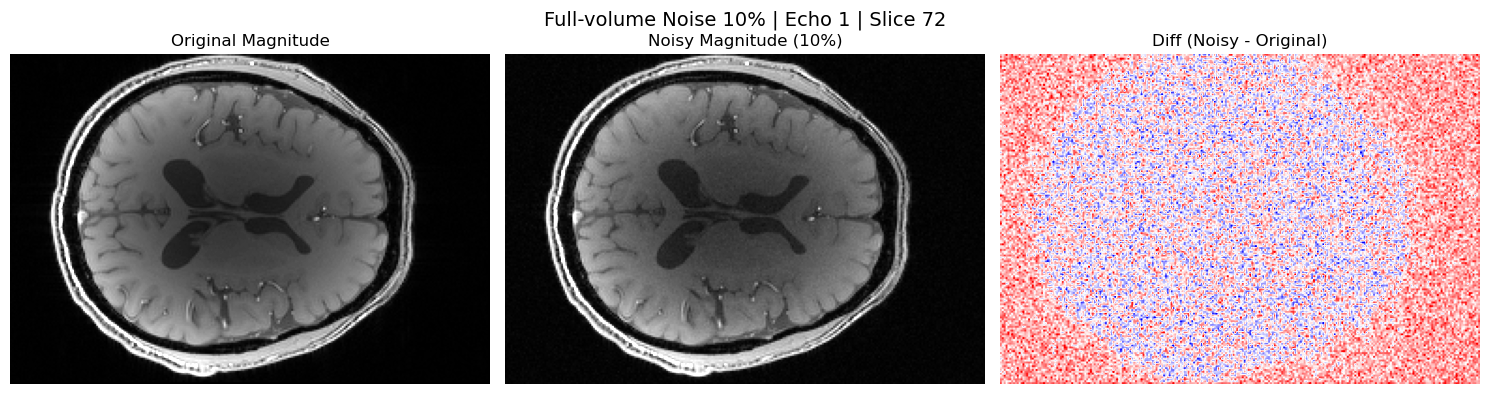

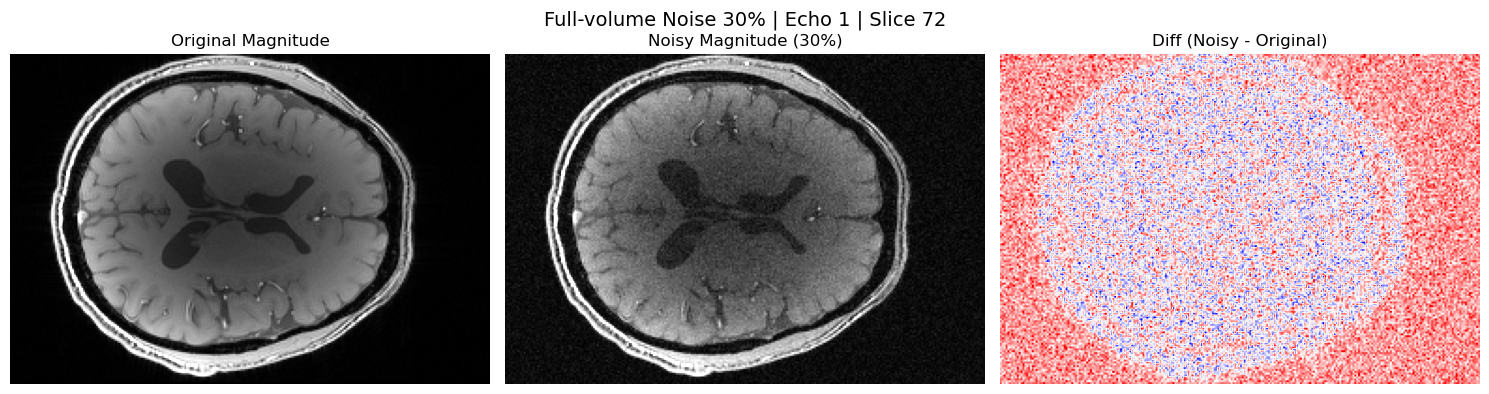

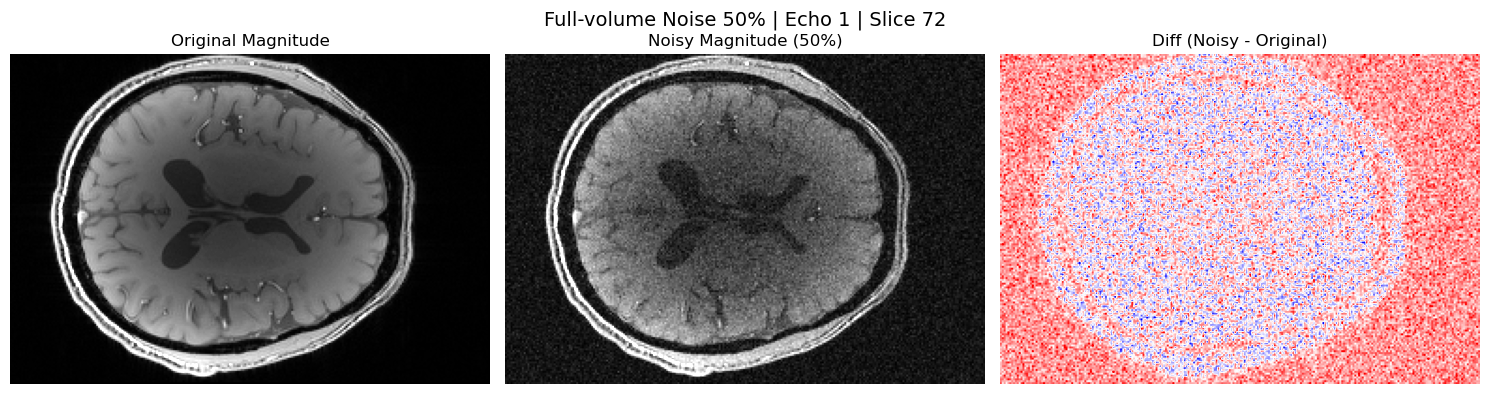

In [14]:
echo_idx = 0
slice_idx = meas_gre.shape[2] // 2

orig_mag = np.abs(meas_gre).astype(np.float32)

# 모든 noise level에서 동일한 display range 사용
orig_2d_ref = orig_mag[:, :, slice_idx, echo_idx]
vmin, vmax = np.percentile(orig_2d_ref, (1, 99))

for noise_percent in [10, 30, 50]:
    noisy_complex = results[noise_percent]["noisy_complex"]
    noisy_mag = np.abs(noisy_complex).astype(np.float32)

    orig_2d = orig_mag[:, :, slice_idx, echo_idx]
    noisy_2d = noisy_mag[:, :, slice_idx, echo_idx]
    diff_2d = noisy_2d - orig_2d

    dv = np.percentile(np.abs(diff_2d), 99)
    dv = max(float(dv), 1e-8)

    fig, ax = plt.subplots(1, 3, figsize=(15, 4))

    ax[0].imshow(orig_2d, cmap="gray", vmin=vmin, vmax=vmax)
    ax[0].set_title("Original Magnitude")

    ax[1].imshow(noisy_2d, cmap="gray", vmin=vmin, vmax=vmax)
    ax[1].set_title(f"Noisy Magnitude ({noise_percent}%)")

    ax[2].imshow(diff_2d, cmap="bwr", vmin=-dv, vmax=dv)
    ax[2].set_title("Diff (Noisy - Original)")

    for a in ax:
        a.axis("off")

    fig.suptitle(
        f"Full-volume Noise {noise_percent}% | "
        f"Echo {echo_idx + 1} | Slice {slice_idx}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()


## 6. 생성 결과 요약

이 노트북의 최종 원칙:

- Noise: 전체 `(X,Y,Z,5)` complex GRE에 추가
- Sigma 기준: 전체 volume의 평균 magnitude
- Brain mask: noise 생성에는 사용하지 않음
- Brain mask: 향후 PSNR / SSIM / NRMSE / HFEN 평가 ROI로만 사용


In [16]:
print("===== Noise dataset summary =====")
print("Original shape :", meas_gre.shape)
print("Number echoes  :", n_echoes)
print("Mean magnitude :", overall_mean)
print("Noise region   : FULL VOLUME")
print("Mask usage     : EVALUATION ONLY")
print()

for noise_percent in [10, 30, 50]:
    r = results[noise_percent]
    print(
        f"{noise_percent:>2}% | "
        f"sigma/component = {r['sigma']:.6f} | "
        f"dtype = {r['noisy_complex'].dtype}"
    )


===== Noise dataset summary =====
Original shape : (176, 256, 144, 5)
Number echoes  : 5
Mean magnitude : 123.05054168701172
Noise region   : FULL VOLUME
Mask usage     : EVALUATION ONLY

10% | sigma/component = 12.305054 | dtype = complex64
30% | sigma/component = 36.915163 | dtype = complex64
50% | sigma/component = 61.525271 | dtype = complex64
